<a href="https://colab.research.google.com/github/Sahil0hi/generative-fourier-reconstruction/blob/main/Stage_3_gen_ai.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Running on device: cpu
Loading OrganAMNIST dataset...
Fitting PCA prior (rank r = 32)...
PCA fit complete.

Running sweep across 4 measurement counts...

STAGE 3 REPRODUCTION BASELINE SWEEP (ORGANAMNIST)
 Coefficients (m)          Sampling Ratio  Zero-Filling MSE           PCA MSE Zero-Filling PSNR (dB) PCA PSNR (dB) PSNR Gain (dB)
              112          14.3% (4 rows) 0.02609 ± 0.01152 0.04763 ± 0.02656                  16.36         13.91          -2.44
              196 25.0% (7 rows - Target) 0.01831 ± 0.00834 0.02593 ± 0.01210                  17.91         16.40          -1.51
              392         50.0% (14 rows) 0.00835 ± 0.00371 0.02273 ± 0.01024                  21.31         16.95          -4.36
              588         75.0% (21 rows) 0.00330 ± 0.00159 0.02270 ± 0.01023                  25.41         16.95          -8.45


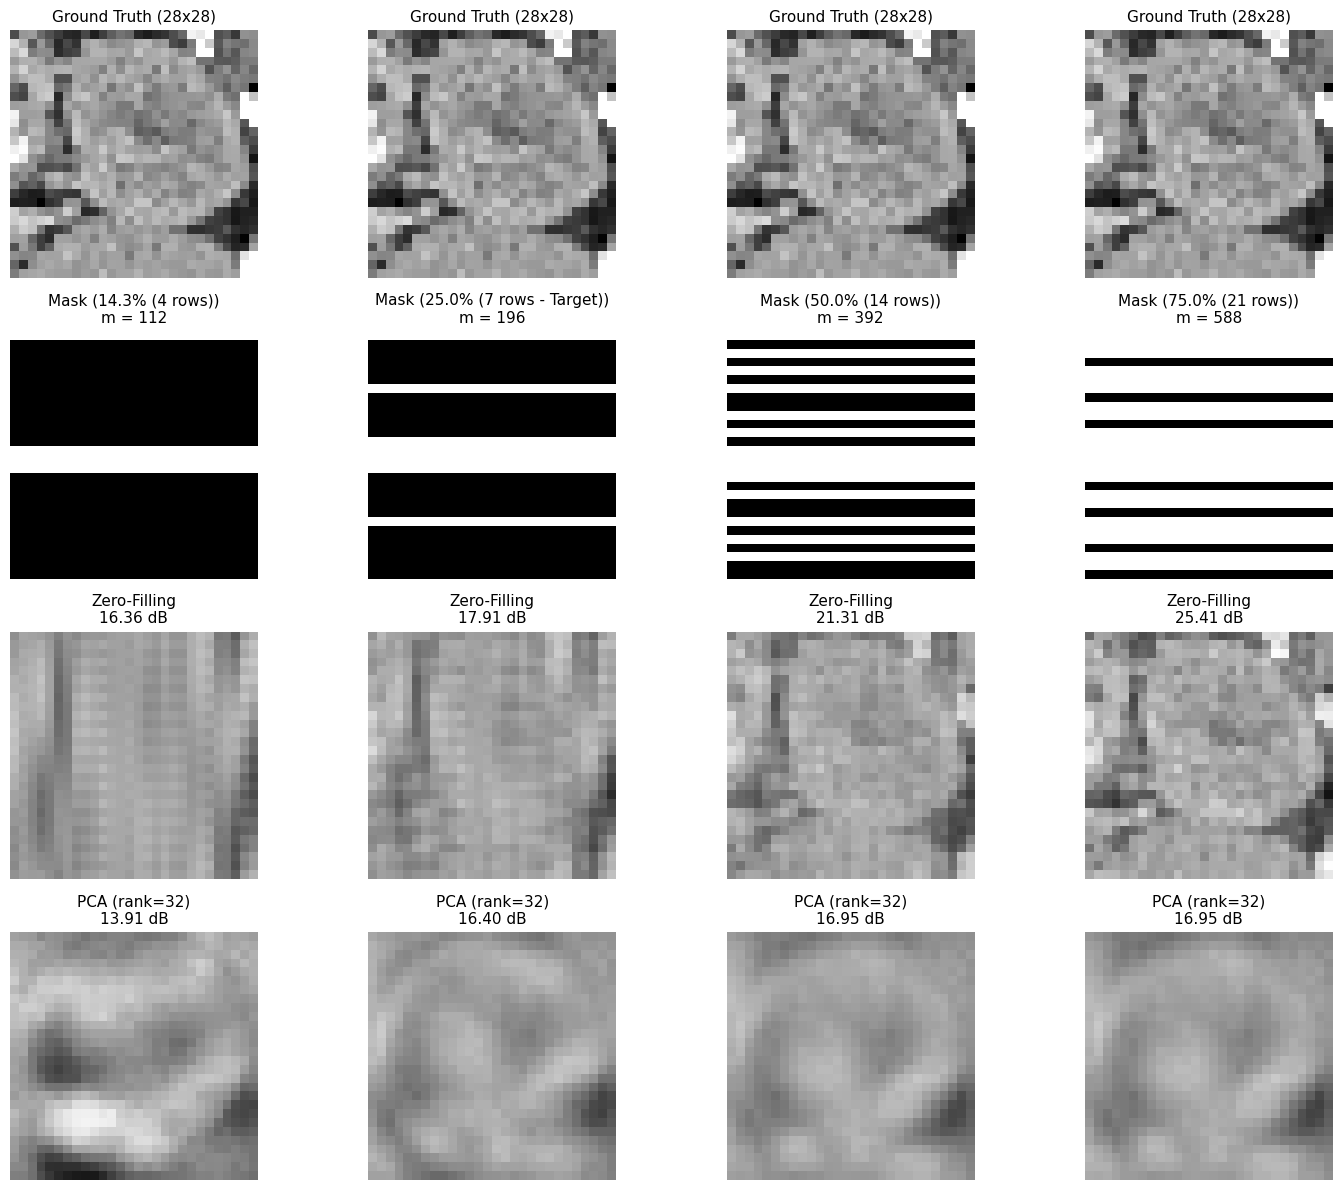

Saved comparison figure as 'stage3_baseline_sweep.png'.


In [11]:
# ==============================================================================
# Stage 3: Baseline Sweep on OrganAMNIST (PCA vs. Zero-Filling)
# Dataset: OrganAMNIST (28 x 28)
# Measurements: m in [112, 196, 392, 588] complex Fourier coefficients
# Baselines: Zero-Filling vs. PCA Subspace Prior (r = 32, lambda = 0.01)
# ==============================================================================

# 1. Install MedMNIST dependency
!pip install medmnist -q

import torch
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from medmnist import OrganAMNIST

# Set random seed for reproducibility
torch.manual_seed(42)
np.random.seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Running on device: {device}")

# ------------------------------------------------------------------------------
# 1. Load OrganAMNIST (2,000 train, 200 held-out test)
# ------------------------------------------------------------------------------
print("Loading OrganAMNIST dataset...")
train_dataset = OrganAMNIST(split='train', download=True)
test_dataset = OrganAMNIST(split='test', download=True)

# Normalize to [0.0, 1.0]
train_images = train_dataset.imgs[:2000].astype(np.float32) / 255.0
test_images = test_dataset.imgs[:200].astype(np.float32) / 255.0
H = W = 28
AXES = (-2, -1)

# ------------------------------------------------------------------------------
# 2. Fourier Operators (From stage1_partner.ipynb)
# ------------------------------------------------------------------------------
def fft2c(images):
    """Centered orthonormal 2D Fourier Transform."""
    return np.fft.fftshift(
        np.fft.fft2(np.fft.ifftshift(images, axes=AXES), axes=AXES, norm="ortho"),
        axes=AXES
    )

def ifft2c(kspace):
    """Centered orthonormal 2D Inverse Fourier Transform."""
    return np.fft.fftshift(
        np.fft.ifft2(np.fft.ifftshift(kspace, axes=AXES), axes=AXES, norm="ortho"),
        axes=AXES
    )

def psnr(reference, reconstruction):
    """PSNR with fixed data range 1.0."""
    mse = np.mean((reference - reconstruction) ** 2, axis=AXES)
    with np.errstate(divide="ignore"):
        return 10.0 * np.log10(1.0 / np.maximum(mse, 1e-12))

# ------------------------------------------------------------------------------
# 3. Fit PCA Prior (Rank r = 32, from stage1_partner.ipynb)
# ------------------------------------------------------------------------------
print("Fitting PCA prior (rank r = 32)...")
rank = 32
ridge = 0.01

pca = PCA(n_components=rank, svd_solver="randomized", random_state=42)
pca.fit(train_images.reshape(len(train_images), -1))

mean_image = pca.mean_.reshape(H, W)
components_image = pca.components_.reshape(-1, H, W)
print("PCA fit complete.")

# ------------------------------------------------------------------------------
# 4. Row Mask Generator with Fully-Sampled Center
# ------------------------------------------------------------------------------
def create_row_mask(H, W, n_rows, central_lines=3):
    mask = np.zeros((H, W), dtype=bool)
    center = H // 2
    c_lines = min(n_rows, central_lines)
    start = center - c_lines // 2
    central = np.arange(start, start + c_lines)
    outside = np.setdiff1d(np.arange(H), central)
    extra_count = n_rows - len(central)

    if extra_count > 0:
        # Uniformly space the remaining lines
        step = len(outside) / extra_count
        selected = [outside[int(i * step)] for i in range(extra_count)]
        sampled_rows = np.sort(np.concatenate([central, selected]))
    else:
        sampled_rows = central

    mask[sampled_rows, :] = True
    return mask

# ------------------------------------------------------------------------------
# 5. Sweep Across 4 Measurement Configurations
# ------------------------------------------------------------------------------
sweep_configs = [
    {"rows": 4, "m": 112, "label": "14.3% (4 rows)"},
    {"rows": 7, "m": 196, "label": "25.0% (7 rows - Target)"},
    {"rows": 14, "m": 392, "label": "50.0% (14 rows)"},
    {"rows": 21, "m": 588, "label": "75.0% (21 rows)"}
]

table_rows = []
reconstructions_sample = {}
test_kspace = fft2c(test_images)

print("\nRunning sweep across 4 measurement counts...")
for cfg in sweep_configs:
    m = cfg["m"]
    mask = create_row_mask(H, W, cfg["rows"])

    # --------------------------------------------------------------------------
    # A. Zero-Filling Reconstruction
    # --------------------------------------------------------------------------
    y_full = test_kspace * mask
    x_zf = ifft2c(y_full).real

    # --------------------------------------------------------------------------
    # B. PCA Reconstruction (Using stage1_partner.ipynb least-squares design)
    # --------------------------------------------------------------------------
    mean_measured = fft2c(mean_image)[mask]
    basis_measured = fft2c(components_image)[:, mask].T  # (m, rank)
    test_measurements = test_kspace[:, mask]             # (200, m)

    # Stack real and imaginary channels
    design = np.concatenate([basis_measured.real, basis_measured.imag], axis=0)  # (2m, rank)
    centered = test_measurements - mean_measured
    target = np.concatenate([centered.real, centered.imag], axis=1).T            # (2m, 200)

    # Add ridge regularization
    if ridge > 0:
        design_reg = np.vstack([design, np.sqrt(ridge) * np.eye(rank)])
        target_reg = np.vstack([target, np.zeros((rank, target.shape[1]))])
    else:
        design_reg = design
        target_reg = target

    # Solve linear least squares
    coefficients = np.linalg.lstsq(design_reg, target_reg, rcond=1e-10)[0].T  # (200, rank)
    x_pca = (pca.mean_ + coefficients @ pca.components_[:rank]).reshape(-1, H, W)

    # --------------------------------------------------------------------------
    # C. Compute Metrics
    # --------------------------------------------------------------------------
    mse_zf = np.mean((test_images - x_zf) ** 2, axis=AXES)
    mse_pca = np.mean((test_images - x_pca) ** 2, axis=AXES)
    psnr_zf = psnr(test_images, x_zf)
    psnr_pca = psnr(test_images, x_pca)

    table_rows.append({
        "Coefficients (m)": m,
        "Sampling Ratio": cfg["label"],
        "Zero-Filling MSE": f"{np.mean(mse_zf):.5f} ± {np.std(mse_zf):.5f}",
        "PCA MSE": f"{np.mean(mse_pca):.5f} ± {np.std(mse_pca):.5f}",
        "Zero-Filling PSNR (dB)": f"{np.mean(psnr_zf):.2f}",
        "PCA PSNR (dB)": f"{np.mean(psnr_pca):.2f}",
        "PSNR Gain (dB)": f"{np.mean(psnr_pca) - np.mean(psnr_zf):+.2f}"
    })

    # Save the 1st test image for visual plotting
    reconstructions_sample[m] = {
        "gt": test_images[0],
        "mask": mask,
        "zf": x_zf[0],
        "pca": x_pca[0]
    }

# ------------------------------------------------------------------------------
# 6. Display Results Table
# ------------------------------------------------------------------------------
df = pd.DataFrame(table_rows)
print("\n" + "="*85)
print("STAGE 3 REPRODUCTION BASELINE SWEEP (ORGANAMNIST)")
print("="*85)
print(df.to_string(index=False))
print("="*85)

# ------------------------------------------------------------------------------
# 7. Generate Figure
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(4, 4, figsize=(15, 12))

for col, cfg in enumerate(sweep_configs):
    m = cfg["m"]

    # Row 0: Ground Truth
    axes[0, col].imshow(reconstructions_sample[m]["gt"], cmap="gray")
    axes[0, col].set_title("Ground Truth (28x28)", fontsize=11, pad=6)
    axes[0, col].axis("off")

    # Row 1: Sampling Mask
    axes[1, col].imshow(reconstructions_sample[m]["mask"], cmap="gray")
    axes[1, col].set_title(f"Mask ({cfg['label']})\nm = {m}", fontsize=11)
    axes[1, col].axis("off")

    # Row 2: Zero-Filling
    axes[2, col].imshow(reconstructions_sample[m]["zf"], cmap="gray", vmin=0, vmax=1)
    axes[2, col].set_title(f"Zero-Filling\n{df.loc[col, 'Zero-Filling PSNR (dB)']} dB", fontsize=11)
    axes[2, col].axis("off")

    # Row 3: PCA Reconstruction
    axes[3, col].imshow(reconstructions_sample[m]["pca"], cmap="gray", vmin=0, vmax=1)
    axes[3, col].set_title(f"PCA (rank=32)\n{df.loc[col, 'PCA PSNR (dB)']} dB", fontsize=11)
    axes[3, col].axis("off")

plt.tight_layout()
plt.savefig("stage3_baseline_sweep.png", dpi=200)
plt.show()
print("Saved comparison figure as 'stage3_baseline_sweep.png'.")

#Load OrganAMNIST
Downloads OrganAMNIST, grabs $2,000$ training images to learn the PCA prior and $200$ held-out test images for evaluation, and divides pixel values by 255.0 to normalize to [0,1]

In [13]:
# ------------------------------------------------------------------------------
# 1. Load OrganAMNIST (2,000 train, 200 held-out test)
# ------------------------------------------------------------------------------
print("Loading OrganAMNIST dataset...")
train_dataset = OrganAMNIST(split='train', download=True)
test_dataset = OrganAMNIST(split='test', download=True)

# Normalize to [0.0, 1.0]
train_images = train_dataset.imgs[:2000].astype(np.float32) / 255.0
test_images = test_dataset.imgs[:200].astype(np.float32) / 255.0
H = W = 28
AXES = (-2, -1)

Loading OrganAMNIST dataset...


covert images into k-space and back. Computes PSNR from MSE.
$\text{MSE} = \text{mean}((x - \hat{x})^2)$) via $10 \log_{10}(1 / \text{MSE})$. Higher PSNR means a cleaner reconstruction.

In [14]:
# ------------------------------------------------------------------------------
# 2. Fourier Operators (From stage1_partner.ipynb)
# ------------------------------------------------------------------------------
def fft2c(images):
    """Centered orthonormal 2D Fourier Transform."""
    return np.fft.fftshift(
        np.fft.fft2(np.fft.ifftshift(images, axes=AXES), axes=AXES, norm="ortho"),
        axes=AXES
    )

def ifft2c(kspace):
    """Centered orthonormal 2D Inverse Fourier Transform."""
    return np.fft.fftshift(
        np.fft.ifft2(np.fft.ifftshift(kspace, axes=AXES), axes=AXES, norm="ortho"),
        axes=AXES
    )

def psnr(reference, reconstruction):
    """PSNR with fixed data range 1.0."""
    mse = np.mean((reference - reconstruction) ** 2, axis=AXES)
    with np.errstate(divide="ignore"):
        return 10.0 * np.log10(1.0 / np.maximum(mse, 1e-12))


#PCA fit
Flattens each $28 \times 28$ training image into a $784$-element vector and finds the average organ image $\mu$ (mean_image) plus the top $32$ principal components $U$ (components_image)

any organ image is the average of the organ image plus weighted mix of U (32):
 $x \approx \mu + Uc$.   

In [15]:
# ------------------------------------------------------------------------------
# 3. Fit PCA Prior (Rank r = 32, from stage1_partner.ipynb)
# ------------------------------------------------------------------------------
print("Fitting PCA prior (rank r = 32)...")
rank = 32
ridge = 0.01

pca = PCA(n_components=rank, svd_solver="randomized", random_state=42)
pca.fit(train_images.reshape(len(train_images), -1))

mean_image = pca.mean_.reshape(H, W)
components_image = pca.components_.reshape(-1, H, W)
print("PCA fit complete.")

Fitting PCA prior (rank r = 32)...
PCA fit complete.


#The Fourier Undersampling Mask ($M$)
Simulates an accelerated MRI scan where only n_rows horizontal lines of the $28 \times 28$ frequency grid are measured.   
It always keeps 3 rows in the center (so basic brightness and organ shapes aren't lost) and spaces the remaining rows evenly across the outer high frequencies. Multiplying test_kspace * mask produces our incomplete measurements $y = MF(x)$

In [16]:
# ------------------------------------------------------------------------------
# 4. Row Mask Generator with Fully-Sampled Center
# ------------------------------------------------------------------------------
def create_row_mask(H, W, n_rows, central_lines=3):
    mask = np.zeros((H, W), dtype=bool)
    center = H // 2
    c_lines = min(n_rows, central_lines)
    start = center - c_lines // 2
    central = np.arange(start, start + c_lines)
    outside = np.setdiff1d(np.arange(H), central)
    extra_count = n_rows - len(central)

    if extra_count > 0:
        # Uniformly space the remaining lines
        step = len(outside) / extra_count
        selected = [outside[int(i * step)] for i in range(extra_count)]
        sampled_rows = np.sort(np.concatenate([central, selected]))
    else:
        sampled_rows = central

    mask[sampled_rows, :] = True
    return mask

# 4 measured coeffiecients (m = 112, 196, 392, 588)
For each of the four sampling rates, the loop runs both reconstruction methods across all $200$ test images: zero-filling and PCA.

$$\hat{c} = \arg\min_{c \in \mathbb{R}^{32}} \bigl\Vert{} M F(\mu + U c) - y \bigr\Vert{}_2^2 + \lambda \Vert{}c\Vert{}_2^2 \quad \longrightarrow \quad \hat{x}_{\text{PCA}} = \mu + U\hat{c}$$

Because the Fourier transform $F$ and mask $M$ are linear, we can expand $M F(\mu + U c)$ into two pieces:$$M F(\mu + U c) = M F(\mu) + (M F U)c$$
Substitute that into the minimization problem and move $M F(\mu)$ next to $y$:$$\hat{c} = \arg\min_{c \in \mathbb{R}^{32}} \bigl\Vert{} \underbrace{(M F U)}_{\text{matrix } B}\, c \;-\; \underbrace{(y - M F(\mu))}_{\text{vector } \tilde{y}} \bigr\Vert{}_2^2 + \lambda \Vert{}c\Vert{}_2^2$$


*   $M F(\mu)$ - masked fourier transform of mean image $\mu$
      * (m,)
*   $B = M F U$ - Masked Fourier transform of the 32 PCA basis images
      * (m, 32)
*   $y$ - The $m$ observed Fourier measurements of the test image
      * (200,m)
*   $\tilde{y} = y - M F(\mu)$ - measuremnets after subtracting the mean
      * (200,m)




In [17]:
# ------------------------------------------------------------------------------
# 5. Sweep Across 4 Measurement Configurations
# ------------------------------------------------------------------------------
sweep_configs = [
    {"rows": 4, "m": 112, "label": "14.3% (4 rows)"},
    {"rows": 7, "m": 196, "label": "25.0% (7 rows - Target)"},
    {"rows": 14, "m": 392, "label": "50.0% (14 rows)"},
    {"rows": 21, "m": 588, "label": "75.0% (21 rows)"}
]

table_rows = []
reconstructions_sample = {}
test_kspace = fft2c(test_images)

print("\nRunning sweep across 4 measurement counts...")
for cfg in sweep_configs:
    m = cfg["m"]
    mask = create_row_mask(H, W, cfg["rows"])

    # --------------------------------------------------------------------------
    # A. Zero-Filling Reconstruction
    # --------------------------------------------------------------------------
    y_full = test_kspace * mask
    x_zf = ifft2c(y_full).real
# Leaves every unmeasured frequency line set to 0 and immediately runs an inverse 2D FFT
    # --------------------------------------------------------------------------
    # B. PCA Reconstruction (Using stage1_partner.ipynb least-squares design)
    # --------------------------------------------------------------------------
    mean_measured = fft2c(mean_image)[mask]
    basis_measured = fft2c(components_image)[:, mask].T  # (m, rank)
    test_measurements = test_kspace[:, mask]             # (200, m)

    # Stack real and imaginary channels
    design = np.concatenate([basis_measured.real, basis_measured.imag], axis=0)  # (2m, rank)
    centered = test_measurements - mean_measured
    target = np.concatenate([centered.real, centered.imag], axis=1).T            # (2m, 200)

    # Add ridge regularization
    if ridge > 0:
        design_reg = np.vstack([design, np.sqrt(ridge) * np.eye(rank)])
        target_reg = np.vstack([target, np.zeros((rank, target.shape[1]))])
    else:
        design_reg = design
        target_reg = target

    # Solve linear least squares
    coefficients = np.linalg.lstsq(design_reg, target_reg, rcond=1e-10)[0].T  # (200, rank) c hat
    x_pca = (pca.mean_ + coefficients @ pca.components_[:rank]).reshape(-1, H, W)


Running sweep across 4 measurement counts...


 PCA =$\mu + U\hat{c}$.   


Running sweep across 4 measurement counts...

STAGE 3 REPRODUCTION BASELINE SWEEP (ORGANAMNIST)
 Coefficients (m)          Sampling Ratio  Zero-Filling MSE           PCA MSE Zero-Filling PSNR (dB) PCA PSNR (dB) PSNR Gain (dB)
              112          14.3% (4 rows) 0.02609 ± 0.01152 0.04763 ± 0.02656                  16.36         13.91          -2.44
              196 25.0% (7 rows - Target) 0.01831 ± 0.00834 0.02593 ± 0.01210                  17.91         16.40          -1.51
              392         50.0% (14 rows) 0.00835 ± 0.00371 0.02273 ± 0.01024                  21.31         16.95          -4.36
              588         75.0% (21 rows) 0.00330 ± 0.00159 0.02270 ± 0.01023                  25.41         16.95          -8.45


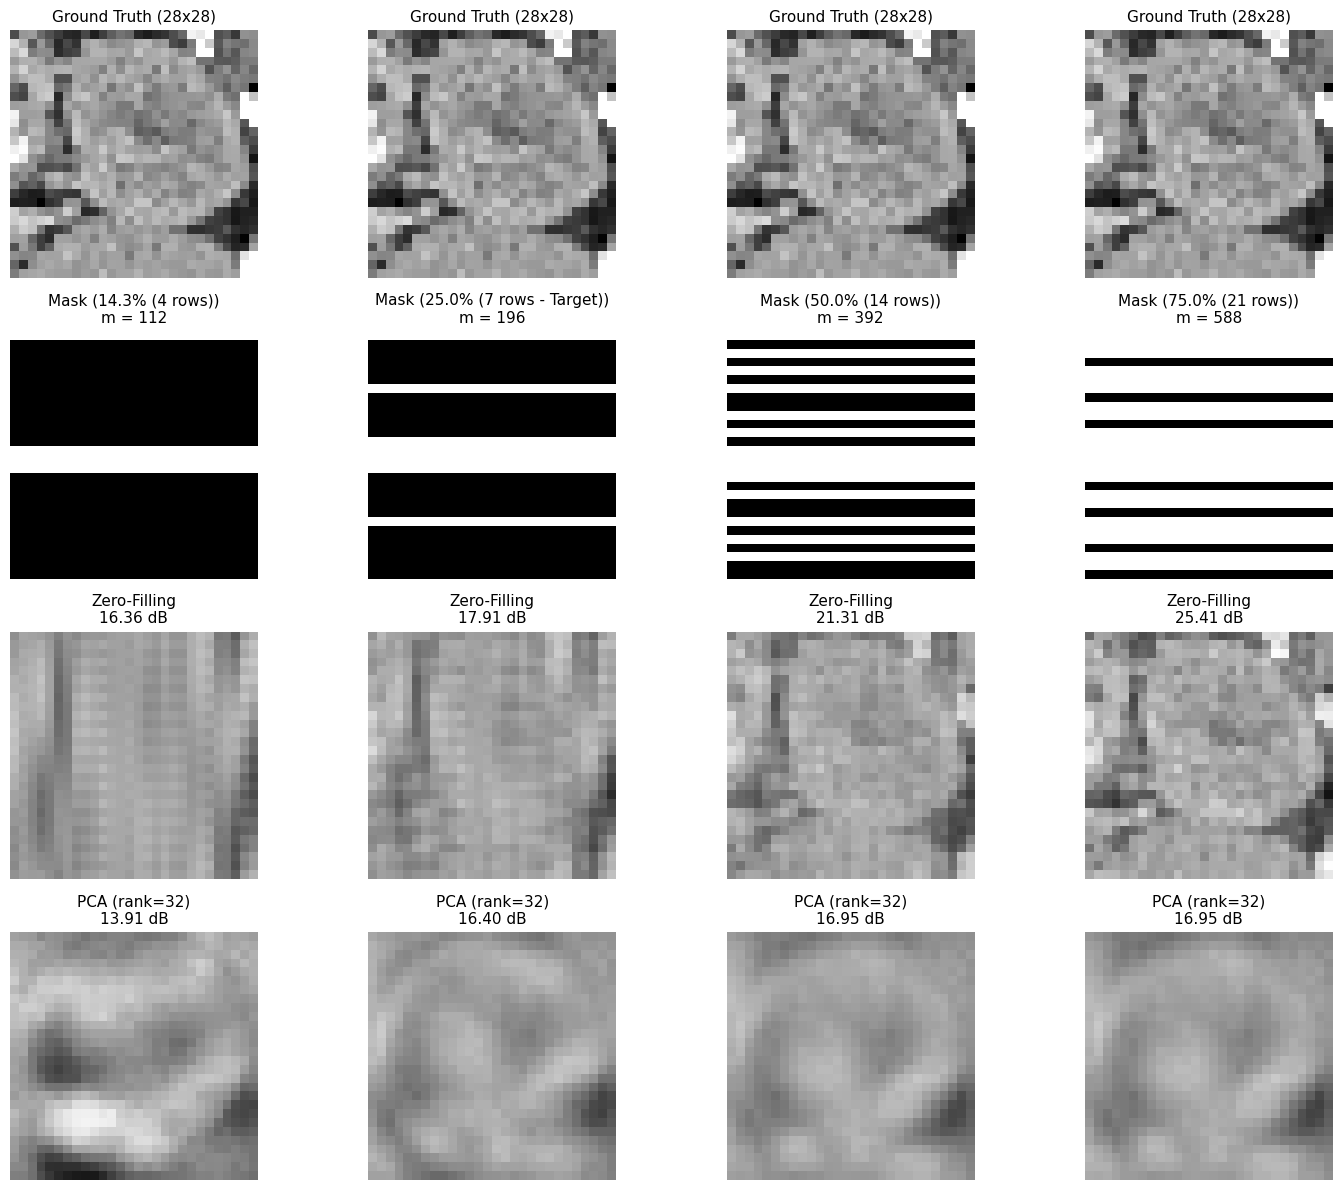

Saved comparison figure as 'stage3_baseline_sweep.png'.


In [21]:
# ------------------------------------------------------------------------------
# 5. Sweep Across 4 Measurement Configurations (Unified Loop & Evaluation)
# ------------------------------------------------------------------------------
sweep_configs = [
    {"rows": 4, "m": 112, "label": "14.3% (4 rows)"},
    {"rows": 7, "m": 196, "label": "25.0% (7 rows - Target)"},
    {"rows": 14, "m": 392, "label": "50.0% (14 rows)"},
    {"rows": 21, "m": 588, "label": "75.0% (21 rows)"}
]

table_rows = []
reconstructions_sample = {}
test_kspace = fft2c(test_images)

print("\nRunning sweep across 4 measurement counts...")
for cfg in sweep_configs:
    m = cfg["m"]
    mask = create_row_mask(H, W, cfg["rows"])

    # --------------------------------------------------------------------------
    # A. Zero-Filling Reconstruction
    # --------------------------------------------------------------------------
    y_full = test_kspace * mask
    x_zf = ifft2c(y_full).real

    # --------------------------------------------------------------------------
    # B. PCA Reconstruction
    # --------------------------------------------------------------------------
    mean_measured = fft2c(mean_image)[mask]
    basis_measured = fft2c(components_image)[:, mask].T  # (m, rank)
    test_measurements = test_kspace[:, mask]             # (200, m)

    # Stack real and imaginary channels
    design = np.concatenate([basis_measured.real, basis_measured.imag], axis=0)  # (2m, rank)
    centered = test_measurements - mean_measured
    target = np.concatenate([centered.real, centered.imag], axis=1).T            # (2m, 200)

    # Add ridge regularization
    if ridge > 0:
        design_reg = np.vstack([design, np.sqrt(ridge) * np.eye(rank)])
        target_reg = np.vstack([target, np.zeros((rank, target.shape[1]))])
    else:
        design_reg = design
        target_reg = target

    # Solve linear least squares
    coefficients = np.linalg.lstsq(design_reg, target_reg, rcond=1e-10)[0].T  # (200, rank)
    x_pca = (pca.mean_ + coefficients @ pca.components_[:rank]).reshape(-1, H, W)

    # --------------------------------------------------------------------------
    # C. Compute Metrics
    # --------------------------------------------------------------------------
    mse_zf = np.mean((test_images - x_zf) ** 2, axis=AXES)
    mse_pca = np.mean((test_images - x_pca) ** 2, axis=AXES)
    psnr_zf = psnr(test_images, x_zf)
    psnr_pca = psnr(test_images, x_pca)

    table_rows.append({
        "Coefficients (m)": m,
        "Sampling Ratio": cfg["label"],
        "Zero-Filling MSE": f"{np.mean(mse_zf):.5f} ± {np.std(mse_zf):.5f}",
        "PCA MSE": f"{np.mean(mse_pca):.5f} ± {np.std(mse_pca):.5f}",
        "Zero-Filling PSNR (dB)": f"{np.mean(psnr_zf):.2f}",
        "PCA PSNR (dB)": f"{np.mean(psnr_pca):.2f}",
        "PSNR Gain (dB)": f"{np.mean(psnr_pca) - np.mean(psnr_zf):+.2f}"
    })

    # Save the 1st test image for visual plotting
    reconstructions_sample[m] = {
        "gt": test_images[0],
        "mask": mask,
        "zf": x_zf[0],
        "pca": x_pca[0]
    }

# ------------------------------------------------------------------------------
# 6. Display Results Table
# ------------------------------------------------------------------------------
df = pd.DataFrame(table_rows)
print("\n" + "="*85)
print("STAGE 3 REPRODUCTION BASELINE SWEEP (ORGANAMNIST)")
print("="*85)
print(df.to_string(index=False))
print("="*85)

# ------------------------------------------------------------------------------
# 7. Generate Figure
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(4, 4, figsize=(15, 12))

for col, cfg in enumerate(sweep_configs):
    m = cfg["m"]

    # Row 0: Ground Truth
    axes[0, col].imshow(reconstructions_sample[m]["gt"], cmap="gray")
    axes[0, col].set_title("Ground Truth (28x28)", fontsize=11, pad=6)
    axes[0, col].axis("off")

    # Row 1: Sampling Mask
    axes[1, col].imshow(reconstructions_sample[m]["mask"], cmap="gray")
    axes[1, col].set_title(f"Mask ({cfg['label']})\nm = {m}", fontsize=11)
    axes[1, col].axis("off")

    # Row 2: Zero-Filling
    axes[2, col].imshow(reconstructions_sample[m]["zf"], cmap="gray", vmin=0, vmax=1)
    axes[2, col].set_title(f"Zero-Filling\n{df.loc[col, 'Zero-Filling PSNR (dB)']} dB", fontsize=11)
    axes[2, col].axis("off")

    # Row 3: PCA Reconstruction
    axes[3, col].imshow(reconstructions_sample[m]["pca"], cmap="gray", vmin=0, vmax=1)
    axes[3, col].set_title(f"PCA (rank={rank})\n{df.loc[col, 'PCA PSNR (dB)']} dB", fontsize=11)
    axes[3, col].axis("off")

plt.tight_layout()
plt.savefig("stage3_baseline_sweep.png", dpi=200)
plt.show()
print("Saved comparison figure as 'stage3_baseline_sweep.png'.")